In [43]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


In [2]:
# standardscaler
num_features = [
    'age', 'resting_blood_pressure', 'cholesterol', 
    'maximum_heart_rate', 'ST_depression'
]

#OneHotEncoder
cat_features = [
    'sex', 'chest_pain_type', 'fasting_blood_sugar', 
    'resting_ecg', 'exercise_angina', 'st_slope', 
    'major_vessels_count', 'thalassemia'
]

In [3]:
# Load the dataset
df = pd.read_csv("..\\Data\\cleaned_heart_disease_data.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 769 entries, 0 to 768
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     769 non-null    int64  
 1   sex                     769 non-null    int64  
 2   chest_pain_type         769 non-null    int64  
 3   resting_blood_pressure  769 non-null    int64  
 4   cholesterol             769 non-null    int64  
 5   fasting_blood_sugar     769 non-null    int64  
 6   resting_ecg             769 non-null    int64  
 7   maximum_heart_rate      769 non-null    int64  
 8   exercise_angina         769 non-null    int64  
 9   ST_depression           769 non-null    float64
 10  st_slope                769 non-null    int64  
 11  major_vessels_count     769 non-null    int64  
 12  thalassemia             769 non-null    int64  
 13  heart_disease           769 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 84.2 KB


In [4]:
# split the dataset into features and target variable
X = df.drop('heart_disease', axis=1)
y = df['heart_disease']

# split the dataset into training(80%), testing(10%), and validation sets(10%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
    )

In [5]:
X_train.shape, X_test.shape, X_val.shape

((615, 13), (77, 13), (77, 13))

In [6]:
def preprocess_data():
    
    num_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    
    cat_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore',drop='first'))
    ])
    
    preprocessor = ColumnTransformer(transformers=[
        ('num', num_pipeline, num_features),    
        ('cat', cat_pipeline, cat_features)     
    ])
    
    return preprocessor
    

In [7]:
preprocess = preprocess_data()
x_train_preprocessed = preprocess.fit_transform(X_train)
x_test_preprocessed = preprocess.transform(X_test)
x_val_preprocessed = preprocess.transform(X_val)

In [8]:
x_train_preprocessed.shape, x_test_preprocessed.shape, x_val_preprocessed.shape

((615, 18), (77, 18), (77, 18))

In [9]:
#  Convert target to array
y_train = np.asarray(y_train).astype(np.float32)
y_test = np.asarray(y_test).astype(np.float32)
y_val = np.asarray(y_val).astype(np.float32)

In [25]:
# TensorFlow is not used in this notebook.
# The model pipeline is built with scikit-learn only.
# Remove the unused TensorFlow import to avoid ModuleNotFoundError.


ModuleNotFoundError: No module named 'tensorflow'

In [16]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.models import Sequential

In [14]:
x_train_preprocessed.shape, x_test_preprocessed.shape, x_val_preprocessed.shape

((615, 18), (77, 18), (77, 18))

In [19]:
model = Sequential([
    Input(shape=(x_train_preprocessed.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])
    

In [20]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,841 (15.00 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
    
)

In [25]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [27]:
history = model.fit(
    x_train_preprocessed, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(x_val_preprocessed, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 80ms/step - accuracy: 0.6000 - loss: 0.6612 - precision: 0.6813 - recall: 0.5074 - val_accuracy: 0.7662 - val_loss: 0.6024 - val_precision: 0.7500 - val_recall: 0.8571
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6927 - loss: 0.5827 - precision: 0.7000 - recall: 0.7685 - val_accuracy: 0.7792 - val_loss: 0.5184 - val_precision: 0.7551 - val_recall: 0.8810
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7642 - loss: 0.5071 - precision: 0.7513 - recall: 0.8516 - val_accuracy: 0.7922 - val_loss: 0.4550 - val_precision: 0.7708 - val_recall: 0.8810
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8114 - loss: 0.4532 - precision: 0.8166 - recall: 0.8457 - val_accuracy: 0.8442 - val_loss: 0.4058 - val_precision: 0.8409 - val_recall: 0.8810
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8195 - loss: 0.4289 - precision: 0.8266 - recall: 0.8487 - val_accuracy: 0.8571 - val_loss: 0.3675

In [29]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'precision', 'recall', 'val_accuracy', 'val_loss', 'val_precision', 'val_recall'])

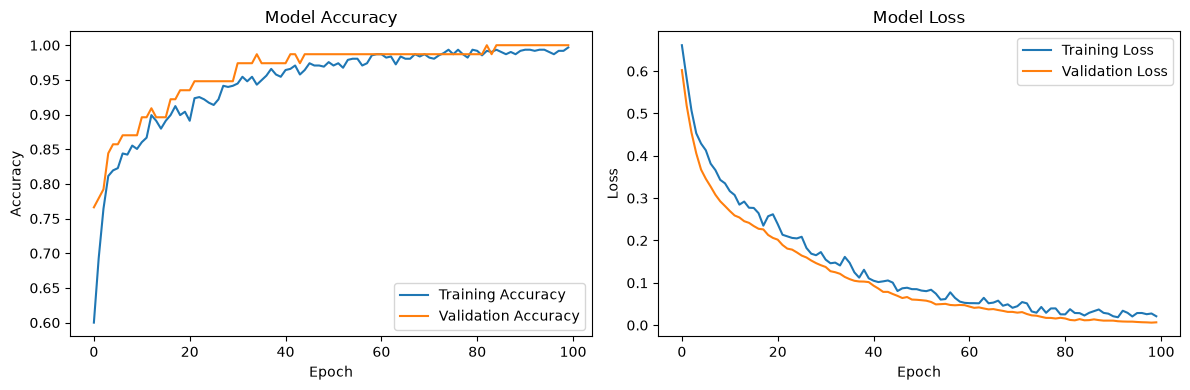

In [30]:
# Plot training history
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [31]:
# Evaluate the model on the test set
test_result = model.evaluate(
    x_test_preprocessed, y_test, verbose=1
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0072 - precision: 1.0000 - recall: 1.0000 


In [33]:
print(f"Test Loss: {test_result[0]:.4f}")
print(f"Test Accuracy: {test_result[1]:.4f}")

Test Loss: 0.0072
Test Accuracy: 1.0000


In [34]:
# Currently, we don't have actual outputs, we have probabilites.
# because sigmoid activation functn gives probabilities
# now lets convert probabilities to binary outputs using a threshold of 0.5

In [35]:
Y_prob = model.predict(x_test_preprocessed)
Y_pred = (Y_prob > 0.5).astype(int)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step


In [37]:
# confusion matrix
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_test, Y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[34  0]
 [ 0 43]]


In [38]:
cr = classification_report(y_test, Y_pred)
print("Classification Report:")
print(cr)

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00        34
         1.0       1.00      1.00      1.00        43

    accuracy                           1.00        77
   macro avg       1.00      1.00      1.00        77
weighted avg       1.00      1.00      1.00        77



In [39]:
# roc_auc curve

from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score


fpr, tpr, thresholds = roc_curve(y_test, Y_prob)
auc = roc_auc_score(y_test, Y_prob)
print("AUC Score:")
print(auc)


AUC Score:
1.0


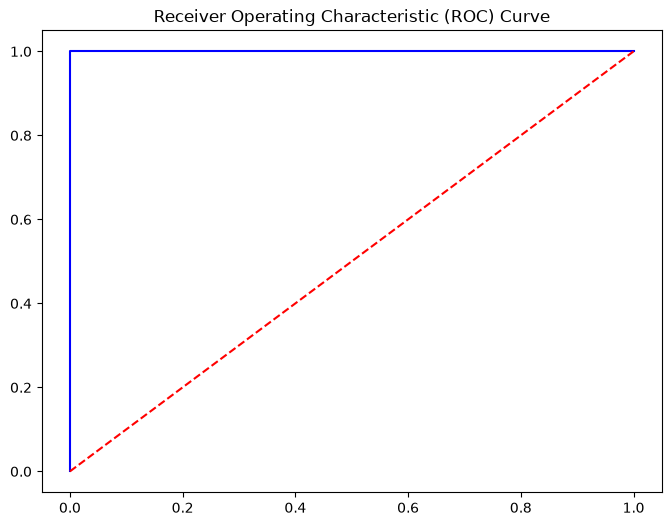

In [40]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Classifier')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.show()

In [41]:
model.save("..\\Models\\heart_disease_model.keras")

In [42]:
# save the preprocessor
import joblib
joblib.dump(preprocess, "..\\Models\\preprocessor.pkl")

['..\\Models\\preprocessor.pkl']

In [44]:
# checking feature names and their unique values

df.columns.to_list()

['age',
 'sex',
 'chest_pain_type',
 'resting_blood_pressure',
 'cholesterol',
 'fasting_blood_sugar',
 'resting_ecg',
 'maximum_heart_rate',
 'exercise_angina',
 'ST_depression',
 'st_slope',
 'major_vessels_count',
 'thalassemia',
 'heart_disease']

In [45]:
cat_features = [
    'sex', 'chest_pain_type', 'fasting_blood_sugar', 
    'resting_ecg', 'exercise_angina', 'st_slope', 
    'major_vessels_count', 'thalassemia'
]

for feature in cat_features:
    unique_values = df[feature].unique()
    print(f"Feature: {feature}, Unique Values: {unique_values}")

Feature: sex, Unique Values: [1 0]
Feature: chest_pain_type, Unique Values: [0 1 2 3]
Feature: fasting_blood_sugar, Unique Values: [0]
Feature: resting_ecg, Unique Values: [1 0 2]
Feature: exercise_angina, Unique Values: [0 1]
Feature: st_slope, Unique Values: [2 0 1]
Feature: major_vessels_count, Unique Values: [2 0 1]
Feature: thalassemia, Unique Values: [3 2 1]


In [46]:
sex_mapping = {"male": 1, "female": 0}
chest_pain_mapping = {"typical angina": 0, "atypical angina": 1, "non-anginal pain": 2, "asymptomatic": 3}
fasting_blood_sugar_mapping = {"true": 1, "false": 0}
resting_ecg_mapping = {"normal": 0, "ST-T wave abnormality": 1, "left ventricular hypertrophy": 2}
exercise_angina_mapping = {"yes": 1, "no": 0}
st_slope_mapping = {"upsloping": 0, "flat": 1, "downsloping": 2}
thalassemia_mapping = {"normal": 0, "fixed defect": 1, "reversible defect": 2}


def map_function(data):
    data['sex'] = data['sex'].map(sex_mapping)
    data['chest_pain_type'] = data['chest_pain_type'].map(chest_pain_mapping)
    data['fasting_blood_sugar'] = data['fasting_blood_sugar'].map(fasting_blood_sugar_mapping)
    data['resting_ecg'] = data['resting_ecg'].map(resting_ecg_mapping)
    data['exercise_angina'] = data['exercise_angina'].map(exercise_angina_mapping)
    data['st_slope'] = data['st_slope'].map(st_slope_mapping)
    data['thalassemia'] = data['thalassemia'].map(thalassemia_mapping)
    return data